# ⚡ The "Fear Gauge" Volatility Spikes: CBOE VIX Telemetry (1990–Present)
## Multi-Decade Asymmetric Jump Processes, Panic Spikes & Mean-Reverting Decays

### 1. Incident Background & Multi-Spike Structure
The **CBOE Volatility Index (VIX)** is Wall Street's premier benchmark for equity market volatility and investor panic, derived from real-time S&P 500 index option prices. 

Unlike prices (which drift upward with economic growth), the VIX is a **stationary, mean-reverting jump-diffusion process**. It idles in quiet, tranquil regimes ($12 \le \text{VIX} \le 20$), but when market liquidity dries up or systemic fear explodes, it exhibits **vertical right-skewed upward spikes** ($40 \rightarrow 85+$), followed by power-law cooling decays.

Major historical panic spikes captured in this 35-year dataset:
* **1990 Gulf War Shock:** VIX spiked to **36.4**.
* **1997 Asian Financial Crisis:** Spike to **38.2**.
* **1998 Russian Debt Default & Long-Term Capital Management (LTCM) Implosion:** VIX reached **45.7**.
* **2001 Dot-Com Bubble Collapse & 9/11 Attacks:** VIX elevated to **43.7**.
* **2002 WorldCom & Enron Corporate Accounting Scandals:** Reached **45.1**.
* **2008 Lehman Brothers / Global Financial Crisis:** Record historic spike to **80.86** close (89.53 intraday).
* **2010 Flash Crash:** Intraday surge to **45.8**.
* **2011 US Credit Rating Downgrade & Eurozone Debt Crisis:** Spiked to **48.0**.
* **February 2018 "Volmageddon":** Single-day surge of **+115%** (largest single-day percentage explosion in history) as inverse volatility products collapsed.
* **March 2020 COVID-19 Panic:** All-time closing record spike to **82.69** on March 16, 2020.
* **August 5, 2024 Yen Carry Trade Unwind:** Intraday explosion to **65.73** (largest opening jump since 2008).

### 2. Target Variables ($y$)
* **`VIX_close`**: Daily CBOE Volatility Index close level.
* **`vix_daily_jump`**: Absolute daily point change ($\Delta y = VIX_t - VIX_{t-1}$).
* **`regime`**: Discrete categorical state (Tranquil, Elevated, Panic, Extreme Crisis).

### 3. Data Source
* Direct Yahoo Finance REST API (`^VIX`, 1990–Present).
* Fully reproducible with offline fallback caching to `./data/`.


### 📚 Academic Citations & Benchmark Lineage
* **Seminal Volatility Index Foundation:** Whaley, R. E. (2000). *"The Investor Fear Gauge."* *The Journal of Portfolio Management*, 26(3), 12–17.
* **Anomaly Benchmark Suite:** Paparrizos, J., Kang, Y., Boniol, P., Tsay, R. S., Palpanas, T., & Franklin, M. J. (2022). *"TSB-UAD: An End-to-End Benchmark Suite for Univariate Time-Series Anomaly Detection."* *Proceedings of the VLDB Endowment (PVLDB)*, 15(9), 1697–1711.
* **BibTeX Citation:**
```bibtex
@article{whaley2000investor,
  title={The Investor Fear Gauge},
  author={Whaley, Robert E},
  journal={The Journal of Portfolio Management},
  volume={26},
  number={3},
  pages={12--17},
  year={2000}
}
@article{paparrizos2022tsbuad,
  title={{TSB-UAD}: An End-to-End Benchmark Suite for Univariate Time-Series Anomaly Detection},
  author={Paparrizos, John and Kang, Yuhao and Boniol, Paul and Tsay, Ruey S and Palpanas, Themis and Franklin, Michael J},
  journal={Proceedings of the VLDB Endowment},
  volume={15},
  number={9},
  pages={1697--1711},
  year={2022}
}
```

In [1]:
import os
import requests
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import find_peaks

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

Environment initialized successfully!


### 4. Data Ingestion & Local Caching

In [2]:
def fetch_vix_telemetry(start_year=1990, cache_dir='data'):
    cache_path = os.path.join(cache_dir, 'cboe_vix_raw.csv')
    
    if os.path.exists(cache_path):
        print(f"Loading cached VIX telemetry from: {cache_path}")
        df = pd.read_csv(cache_path)
        df['date'] = pd.to_datetime(df['date'])
        return df
    
    print(f"Fetching CBOE VIX historical series from {start_year} to present...")
    t1 = int(datetime.datetime(start_year, 1, 1).timestamp())
    t2 = int(datetime.datetime.now().timestamp())
    url = f'https://query1.finance.yahoo.com/v8/finance/chart/%5EVIX?period1={t1}&period2={t2}&interval=1d'
    headers = {'User-Agent': 'Mozilla/5.0'}
    
    response = requests.get(url, headers=headers, timeout=30)
    response.raise_for_status()
    res = response.json()['chart']['result'][0]
    
    dates = pd.to_datetime(res['timestamp'], unit='s').tz_localize(None).floor('D')
    quote = res['indicators']['quote'][0]
    
    df = pd.DataFrame({
        'date': dates,
        'VIX_open': quote['open'],
        'VIX_high': quote['high'],
        'VIX_low': quote['low'],
        'VIX_close': quote['close'],
        'VIX_vol': quote['volume']
    }).dropna(subset=['VIX_close']).drop_duplicates(subset=['date']).sort_values('date').reset_index(drop=True)
    
    df.to_csv(cache_path, index=False)
    print(f"Downloaded and cached {len(df)} trading days of CBOE VIX telemetry.")
    return df

df_vix = fetch_vix_telemetry()
df_vix.head()

Loading cached VIX telemetry from: data/cboe_vix_raw.csv


,date,VIX_open,VIX_high,VIX_low,VIX_close,VIX_vol
0,1990-01-02,17.240000,17.240000,17.240000,17.240000,0.0
1,1990-01-03,18.190001,18.190001,18.190001,18.190001,0.0
2,1990-01-04,19.219999,19.219999,19.219999,19.219999,0.0
3,1990-01-05,20.110001,20.110001,20.110001,20.110001,0.0
4,1990-01-08,20.260000,20.260000,20.260000,20.260000,0.0


### 5. Multi-Spike Feature Engineering & Volatility Regime Segmentation

In [3]:
df_vix_proc = df_vix.copy().sort_values('date').reset_index(drop=True)

# 1. First differences / Point Jump Velocity
df_vix_proc['vix_point_change'] = df_vix_proc['VIX_close'].diff()
df_vix_proc['vix_pct_change'] = df_vix_proc['VIX_close'].pct_change() * 100.0

# 2. Intraday Range / Spread (High - Low)
df_vix_proc['intraday_range'] = df_vix_proc['VIX_high'] - df_vix_proc['VIX_low']

# 3. Rolling 50-day Baseline & Z-Score
roll_mean_50 = df_vix_proc['VIX_close'].rolling(50).mean()
roll_std_50 = df_vix_proc['VIX_close'].rolling(50).std()
df_vix_proc['vix_zscore_50d'] = (df_vix_proc['VIX_close'] - roll_mean_50) / roll_std_50

# 4. Volatility Regime Categorization
# - Tranquil: VIX < 20
# - Elevated: 20 <= VIX < 30
# - Panic / Stress: 30 <= VIX < 50
# - Systemic Crisis: VIX >= 50
conditions = [
    (df_vix_proc['VIX_close'] < 20),
    (df_vix_proc['VIX_close'] >= 20) & (df_vix_proc['VIX_close'] < 30),
    (df_vix_proc['VIX_close'] >= 30) & (df_vix_proc['VIX_close'] < 50),
    (df_vix_proc['VIX_close'] >= 50)
]
choices = ['Tranquil (<20)', 'Elevated (20-30)', 'Panic (30-50)', 'Crisis (>=50)']
df_vix_proc['regime'] = np.select(conditions, choices, default='Tranquil (<20)')

# 5. Automated Peak Detection (Find prominent local spikes)
peak_indices, properties = find_peaks(df_vix_proc['VIX_close'].values, height=35, distance=60, prominence=10)
df_vix_proc['is_spike_peak'] = 0
df_vix_proc.loc[peak_indices, 'is_spike_peak'] = 1

print(f"Total Trading Days Analyzed: {len(df_vix_proc):,}")
print(f"Detected Prominent Panic Peaks (VIX >= 35): {len(peak_indices)}")
print(f"Days in Extreme Crisis Regime (VIX >= 50):   {(df_vix_proc['VIX_close'] >= 50).sum()}")
print(f"All-Time High VIX Close:                    {df_vix_proc['VIX_close'].max():.2f} on {df_vix_proc.loc[df_vix_proc['VIX_close'].idxmax(), 'date'].strftime('%Y-%m-%d')}")
df_vix_proc.head()

Total Trading Days Analyzed: 9,276
Detected Prominent Panic Peaks (VIX >= 35): 21
Days in Extreme Crisis Regime (VIX >= 50):   75
All-Time High VIX Close:                    82.69 on 2020-03-16


,date,VIX_open,VIX_high,VIX_low,VIX_close,VIX_vol,vix_point_change,vix_pct_change,intraday_range,vix_zscore_50d,regime,is_spike_peak
0,1990-01-02,17.240000,17.240000,17.240000,17.240000,0.0,NaN,NaN,0.0,NaN,Tranquil (<20),0
1,1990-01-03,18.190001,18.190001,18.190001,18.190001,0.0,0.950001,5.510445,0.0,NaN,Tranquil (<20),0
2,1990-01-04,19.219999,19.219999,19.219999,19.219999,0.0,1.029999,5.662445,0.0,NaN,Tranquil (<20),0
3,1990-01-05,20.110001,20.110001,20.110001,20.110001,0.0,0.890001,4.630600,0.0,NaN,Elevated (20-30),0
4,1990-01-08,20.260000,20.260000,20.260000,20.260000,0.0,0.150000,0.745896,0.0,NaN,Elevated (20-30),0


### 6. Timeline Visualizations of 35 Years of Volatility Spikes

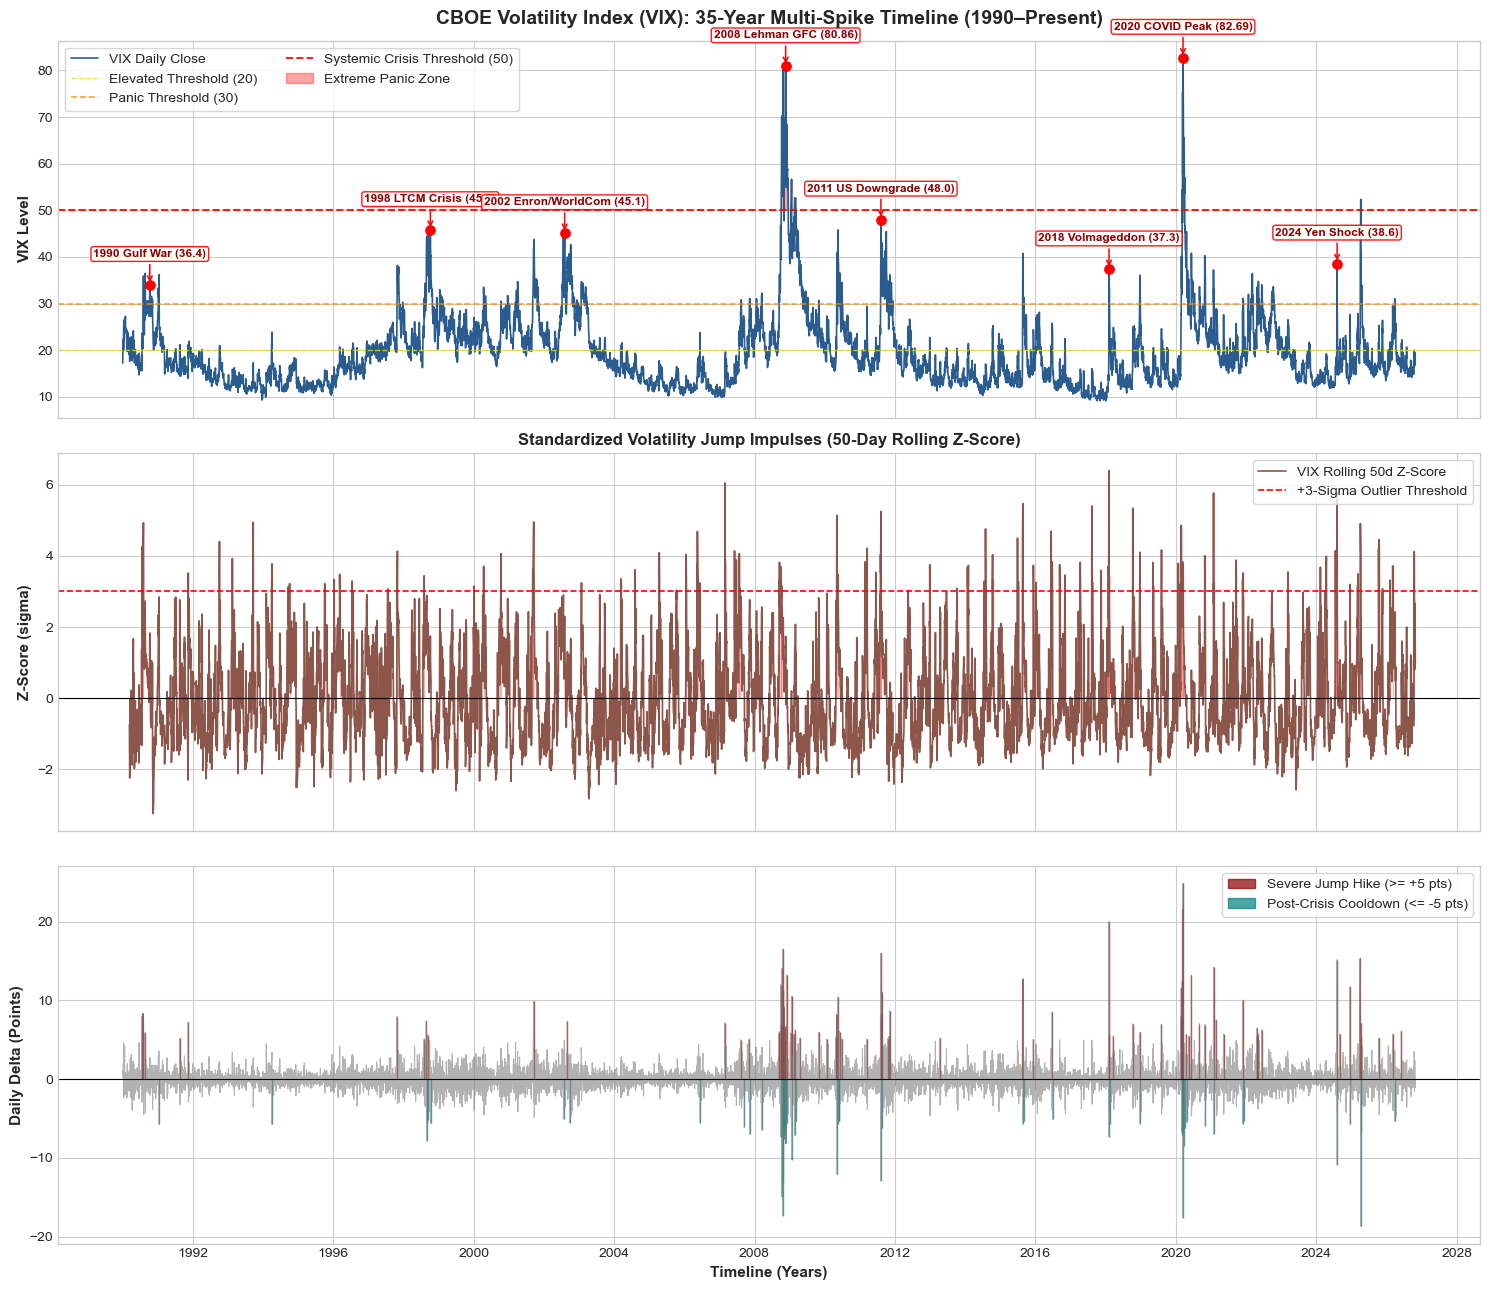

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(15, 13), sharex=True)

# 1. Full 35-Year VIX Heartbeat with Regime Bands
ax1 = axes[0]
ax1.plot(df_vix_proc['date'], df_vix_proc['VIX_close'], color='#2b5c8f', lw=1.2, label='VIX Daily Close')

# Regime thresholds
ax1.axhline(20, color='gold', ls='--', lw=1.0, alpha=0.8, label='Elevated Threshold (20)')
ax1.axhline(30, color='darkorange', ls='--', lw=1.2, alpha=0.8, label='Panic Threshold (30)')
ax1.axhline(50, color='red', ls='--', lw=1.4, alpha=0.9, label='Systemic Crisis Threshold (50)')

# Highlight Crisis Zones (VIX >= 50)
ax1.fill_between(df_vix_proc['date'], 50, df_vix_proc['VIX_close'], 
                 where=(df_vix_proc['VIX_close'] >= 50), color='red', alpha=0.35, label='Extreme Panic Zone')

# Annotate Major Historic Spikes
vix_events = [
    ('1990-10-11', '1990 Gulf War (36.4)', 36.4),
    ('1998-10-08', '1998 LTCM Crisis (45.7)', 45.7),
    ('2002-08-05', '2002 Enron/WorldCom (45.1)', 45.1),
    ('2008-11-20', '2008 Lehman GFC (80.86)', 80.86),
    ('2011-08-08', '2011 US Downgrade (48.0)', 48.0),
    ('2018-02-05', '2018 Volmageddon (37.3)', 37.3),
    ('2020-03-16', '2020 COVID Peak (82.69)', 82.69),
    ('2024-08-05', '2024 Yen Shock (38.6)', 38.6)
]

for date_str, label, y_val in vix_events:
    dt = pd.to_datetime(date_str)
    if dt in df_vix_proc['date'].values:
        actual = df_vix_proc.loc[df_vix_proc['date'] == dt, 'VIX_close'].values[0]
        ax1.scatter(dt, actual, color='red', s=45, zorder=5)
        ax1.annotate(label, xy=(dt, actual), xytext=(dt, actual + 6),
                     arrowprops=dict(arrowstyle="->", color='red', lw=1.1),
                     fontsize=8.5, fontweight='bold', color='#8b0000', ha='center',
                     bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.9, edgecolor='red'))

ax1.set_title("CBOE Volatility Index (VIX): 35-Year Multi-Spike Timeline (1990–Present)", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("VIX Level", fontsize=11, fontweight='bold')
ax1.legend(loc='upper left', frameon=True, ncol=2)

# 2. Rolling 50-Day Z-Score (Departure from Calm Regimes)
ax2 = axes[1]
ax2.plot(df_vix_proc['date'], df_vix_proc['vix_zscore_50d'], color='#8c564b', lw=1.2, label='VIX Rolling 50d Z-Score')
ax2.axhline(0, color='black', lw=0.8)
ax2.axhline(3.0, color='red', ls='--', lw=1.2, label='+3-Sigma Outlier Threshold')
ax2.fill_between(df_vix_proc['date'], 0, df_vix_proc['vix_zscore_50d'], 
                 where=(df_vix_proc['vix_zscore_50d'] > 3.0), color='red', alpha=0.3)
ax2.set_ylabel("Z-Score (sigma)", fontsize=11, fontweight='bold')
ax2.set_title("Standardized Volatility Jump Impulses (50-Day Rolling Z-Score)", fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

# 3. Daily Velocity / Point Changes (Asymmetric Shock Waves)
ax3 = axes[2]
ax3.plot(df_vix_proc['date'], df_vix_proc['vix_point_change'], color='#7f7f7f', lw=0.8, alpha=0.6)
ax3.fill_between(df_vix_proc['date'], 0, df_vix_proc['vix_point_change'], 
                 where=(df_vix_proc['vix_point_change'] >= 5.0), color='darkred', alpha=0.7, label='Severe Jump Hike (>= +5 pts)')
ax3.fill_between(df_vix_proc['date'], 0, df_vix_proc['vix_point_change'], 
                 where=(df_vix_proc['vix_point_change'] <= -5.0), color='teal', alpha=0.7, label='Post-Crisis Cooldown (<= -5 pts)')
ax3.axhline(0, color='black', lw=0.8)
ax3.set_ylabel("Daily Delta (Points)", fontsize=11, fontweight='bold')
ax3.set_xlabel("Timeline (Years)", fontsize=11, fontweight='bold')
ax3.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('data/cboe_vix_timeline.png', dpi=300)
plt.show()

### 7. Statistical Regime Distribution & Peak Ranking Table

In [5]:
# Summary table of the top 12 historic VIX peaks
peak_df = df_vix_proc[df_vix_proc['is_spike_peak'] == 1].sort_values('VIX_close', ascending=False).head(12)
peak_summary = peak_df[['date', 'VIX_close', 'VIX_high', 'vix_point_change', 'vix_zscore_50d', 'regime']].copy()
peak_summary['date'] = peak_summary['date'].dt.strftime('%Y-%m-%d')
print("=== Top Historical CBOE VIX Panic Spike Peaks ===")
print(peak_summary.to_string(index=False))

# Regime breakdown
print("\n=== Historical Regime Distribution ===")
regime_counts = df_vix_proc['regime'].value_counts()
regime_pcts = df_vix_proc['regime'].value_counts(normalize=True) * 100
for reg in ['Tranquil (<20)', 'Elevated (20-30)', 'Panic (30-50)', 'Crisis (>=50)']:
    cnt = regime_counts.get(reg, 0)
    pct = regime_pcts.get(reg, 0.0)
    print(f"  {reg:<20}: {cnt:>5} days ({pct:>5.1f}%)")

# Save processed dataset
out_path = 'data/cboe_vix_processed.csv'
df_vix_proc.to_csv(out_path, index=False)
print(f"\nProcessed VIX dataset successfully saved to: {out_path}")

=== Top Historical CBOE VIX Panic Spike Peaks ===
      date  VIX_close  VIX_high  vix_point_change  vix_zscore_50d        regime
2020-03-16  82.690002 83.559998         24.860001        3.441237 Crisis (>=50)
2008-11-20  80.860001 81.480003          6.599998        1.739310 Crisis (>=50)
2009-03-02  52.650002 53.250000          6.300003        2.076913 Crisis (>=50)
2025-04-08  52.330002 57.520000          5.350002        3.989861 Crisis (>=50)
2011-08-08  48.000000 48.000000         16.000000        5.248103 Panic (30-50)
2010-05-20  45.790001 46.369999         10.470001        3.481818 Panic (30-50)
1998-10-08  45.740002 49.529999          2.230003        1.749437 Panic (30-50)
2002-08-05  45.080002 45.209999          3.790001        2.299385 Panic (30-50)
2001-09-20  43.740002 43.759998          3.180000        3.445512 Panic (30-50)
2020-06-11  40.790001 42.580002         13.220001        0.790190 Panic (30-50)
2015-08-24  40.740002 53.290001         12.710001        5.469050 Pani